In [1]:
!pip install -q kagglehub

In [2]:
!pip install scikit-image

In [3]:
import kagglehub

# Download the Flowers Recognition dataset
path = kagglehub.dataset_download(
    "alxmamaev/flowers-recognition"
)

print("Dataset downloaded to:", path)

Using Colab cache for faster access to the 'flowers-recognition' dataset.
Dataset downloaded to: /kaggle/input/flowers-recognition


In [4]:
import os
# Get the actual flowers directory
flowers_path = os.path.join(path, "flowers")

# Display the class names
print(os.listdir(flowers_path))


['dandelion', 'daisy', 'sunflower', 'tulip', 'rose']


In [5]:

# Count images in each class

for class_name in os.listdir(flowers_path):
    class_path = os.path.join(flowers_path, class_name)

    if os.path.isdir(class_path):
        print(f"{class_name}: {len(os.listdir(class_path))} images")


dandelion: 1052 images
daisy: 764 images
sunflower: 733 images
tulip: 984 images
rose: 784 images


# Select 200 pic from every catagery

In [6]:

import random
import os
import shutil

# Set a fixed random seed
random.seed(42)

# Number of images per class
SAMPLES_PER_CLASS = 200

# Create a new folder for the selected dataset
selected_path = "/content/flowers_selected"
os.makedirs(selected_path, exist_ok=True)

# Select images from each class
for class_name in os.listdir(flowers_path):

    class_path = os.path.join(flowers_path, class_name)

    if not os.path.isdir(class_path):
        continue

    # Get image files only
    images = [
        file for file in os.listdir(class_path)
        if file.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    # Randomly select 200 images
    selected_images = random.sample(
        images, SAMPLES_PER_CLASS
    )

    # Create a folder for this class
    new_class_path = os.path.join(
        selected_path, class_name
    )
    os.makedirs(new_class_path, exist_ok=True)

    # Copy selected images
    for image in selected_images:
        shutil.copy2(
            os.path.join(class_path, image),
            os.path.join(new_class_path, image)
        )

print("Dataset selection completed!")


Dataset selection completed!


In [7]:

for class_name in sorted(os.listdir(selected_path)):
    class_path = os.path.join(selected_path, class_name)

    print(class_name, ":", len(os.listdir(class_path)))

print("Total images:",
      sum(len(os.listdir(os.path.join(selected_path, c)))
          for c in os.listdir(selected_path)))


daisy : 200
dandelion : 200
rose : 200
sunflower : 200
tulip : 200
Total images: 1000


# Remove wrong images and replace them

In [8]:

import os
import shutil
import random
from PIL import Image

# Images identified as irrelevant
wrong_images = {
    "rose": [4, 8, 15, 34, 41, 43, 45, 58, 70, 77, 97, 132, 160],
    "daisy": [33, 83, 107],
    "dandelion": [104],
    "sunflower": [164],
    "tulip": [13, 37, 38, 53, 54, 55, 57, 68, 70, 144, 155]
}

SAMPLES_PER_CLASS = 200
random.seed(42)

# Create a new cleaned dataset folder
cleaned_path = "/content/flowers_cleaned"

if os.path.exists(cleaned_path):
    shutil.rmtree(cleaned_path)

os.makedirs(cleaned_path)

# Check whether an image is valid
def is_valid_image(image_path):
    try:
        with Image.open(image_path) as img:
            img.load()
        return True
    except Exception:
        return False


for class_name in sorted(wrong_images):

    original_class_path = os.path.join(
        flowers_path, class_name
    )

    selected_class_path = os.path.join(
        selected_path, class_name
    )

    new_class_path = os.path.join(
        cleaned_path, class_name
    )

    os.makedirs(new_class_path)

    # Get the same sorted image list used during inspection
    selected_files = sorted([
        f for f in os.listdir(selected_class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])

    # Identify files to remove using their indexes
    bad_indices = set(wrong_images[class_name])

    files_to_remove = {
        selected_files[i] for i in bad_indices
    }

    # Keep valid images that were not identified as wrong
    good_files = []

    for i, filename in enumerate(selected_files):

        if i in bad_indices:
            continue

        source = os.path.join(selected_class_path, filename)

        if is_valid_image(source):
            good_files.append(filename)

    # Copy good images into the cleaned folder
    for filename in good_files:
        shutil.copy2(
            os.path.join(selected_class_path, filename),
            os.path.join(new_class_path, filename)
        )

    # Calculate how many replacement images are needed
    needed = SAMPLES_PER_CLASS - len(good_files)

    # Exclude all previously selected images
    excluded_files = set(selected_files)

    candidates = []

    for filename in sorted(os.listdir(original_class_path)):

        if filename in excluded_files:
            continue

        if not filename.lower().endswith(
            ('.jpg', '.jpeg', '.png')
        ):
            continue

        source = os.path.join(original_class_path, filename)

        if is_valid_image(source):
            candidates.append(filename)

    # Select replacement images
    if len(candidates) < needed:
        raise ValueError(
            f"Not enough replacement images for {class_name}"
        )

    replacements = random.sample(candidates, needed)

    # Copy replacement images
    for filename in replacements:
        shutil.copy2(
            os.path.join(original_class_path, filename),
            os.path.join(new_class_path, filename)
        )

    print(
        f"{class_name}: {len(good_files)} kept + "
        f"{len(replacements)} replaced = "
        f"{len(os.listdir(new_class_path))}"
    )

print("\nCleaning completed successfully!")


daisy: 197 kept + 3 replaced = 200
dandelion: 199 kept + 1 replaced = 200
rose: 187 kept + 13 replaced = 200
sunflower: 199 kept + 1 replaced = 200
tulip: 189 kept + 11 replaced = 200

Cleaning completed successfully!


In [9]:
total_images = 0

for class_name in sorted(os.listdir(cleaned_path)):

    class_path = os.path.join(cleaned_path, class_name)

    count = len([
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])

    total_images += count

    print(f"{class_name}: {count} images")

print("-" * 30)
print("Total images:", total_images)


daisy: 200 images
dandelion: 200 images
rose: 200 images
sunflower: 200 images
tulip: 200 images
------------------------------
Total images: 1000


In [10]:

import os
import hashlib
from collections import defaultdict

hashes = defaultdict(list)

for class_name in sorted(os.listdir(cleaned_path)):

    class_path = os.path.join(cleaned_path, class_name)

    for filename in os.listdir(class_path):

        image_path = os.path.join(class_path, filename)

        # Calculate image hash
        with open(image_path, "rb") as file:
            image_hash = hashlib.md5(file.read()).hexdigest()

        hashes[image_hash].append({
            "class": class_name,
            "filename": filename
        })

# Find duplicated images
duplicates = {
    image_hash: files
    for image_hash, files in hashes.items()
    if len(files) > 1
}

print("Number of duplicated groups:", len(duplicates))

if duplicates:
    for group_number, files in enumerate(duplicates.values(), 1):
        print(f"\nDuplicate Group {group_number}:")

        for file in files:
            print(f"Class: {file['class']} | File: {file['filename']}")
else:
    print("No exact duplicates found!")


Number of duplicated groups: 1

Duplicate Group 1:
Class: rose | File: 15922772266_1167a06620.jpg
Class: tulip | File: 15922772266_1167a06620.jpg


# Check Duplication

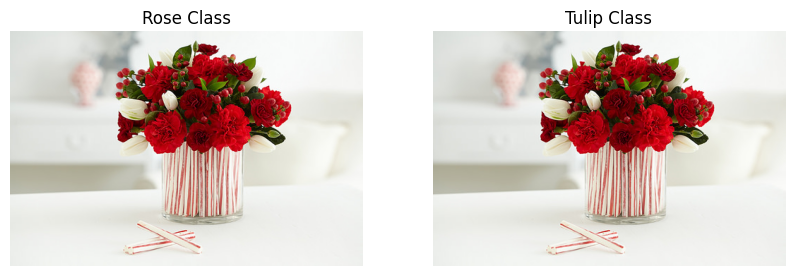

In [11]:

import matplotlib.pyplot as plt
from PIL import Image
import os

filename = "15922772266_1167a06620.jpg"

rose_image = os.path.join(cleaned_path, "rose", filename)
tulip_image = os.path.join(cleaned_path, "tulip", filename)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(Image.open(rose_image))
axes[0].set_title("Rose Class")
axes[0].axis("off")

axes[1].imshow(Image.open(tulip_image))
axes[1].set_title("Tulip Class")
axes[1].axis("off")

plt.show()


In [12]:

import os
import shutil
import random
import hashlib
from PIL import Image

filename = "15922772266_1167a06620.jpg"

# Remove the duplicate from Tulip only
tulip_cleaned_path = os.path.join(cleaned_path, "tulip")
duplicate_path = os.path.join(tulip_cleaned_path, filename)

os.remove(duplicate_path)

# Get hashes of all remaining cleaned images
existing_hashes = set()

for class_name in os.listdir(cleaned_path):
    class_path = os.path.join(cleaned_path, class_name)

    for file in os.listdir(class_path):
        image_path = os.path.join(class_path, file)

        with open(image_path, "rb") as f:
            existing_hashes.add(
                hashlib.md5(f.read()).hexdigest()
            )

# Find a new Tulip image from the original dataset
original_tulip_path = os.path.join(flowers_path, "tulip")

current_tulip_files = set(os.listdir(tulip_cleaned_path))

candidates = []

for file in os.listdir(original_tulip_path):

    if file in current_tulip_files:
        continue

    if not file.lower().endswith((".jpg", ".jpeg", ".png")):
        continue

    image_path = os.path.join(original_tulip_path, file)

    try:
        with Image.open(image_path) as img:
            img.load()

        with open(image_path, "rb") as f:
            image_hash = hashlib.md5(f.read()).hexdigest()

        if image_hash not in existing_hashes:
            candidates.append(file)

    except Exception:
        continue

if not candidates:
    raise ValueError("No suitable replacement image found!")

random.seed(42)
new_image = random.choice(sorted(candidates))

shutil.copy2(
    os.path.join(original_tulip_path, new_image),
    os.path.join(tulip_cleaned_path, new_image)
)

print("Removed duplicate from: tulip")
print("Kept original image in: rose")
print("New Tulip image:", new_image)


Removed duplicate from: tulip
Kept original image in: rose
New Tulip image: 7166550328_de0d73cfa9_n.jpg


In [13]:

from PIL import Image
import os
from collections import Counter

image_modes = Counter()
image_sizes = Counter()
invalid_images = []

for class_name in sorted(os.listdir(cleaned_path)):

    class_path = os.path.join(cleaned_path, class_name)

    for filename in os.listdir(class_path):

        image_path = os.path.join(class_path, filename)

        try:
            with Image.open(image_path) as img:
                image_modes[img.mode] += 1
                image_sizes[img.size] += 1
                img.verify()

        except Exception:
            invalid_images.append(image_path)

print("Image Modes:", image_modes)
print("\nMost common dimensions:")
print(image_sizes.most_common(10))

print("\nInvalid images:", len(invalid_images))


Image Modes: Counter({'RGB': 1000})

Most common dimensions:
[((320, 240), 154), ((500, 333), 117), ((240, 159), 90), ((320, 213), 68), ((240, 240), 59), ((180, 240), 36), ((500, 375), 32), ((159, 240), 28), ((500, 332), 25), ((240, 180), 24)]

Invalid images: 0
